до этого работали ток с координатами кафе но будем теперь работать не только с существующими кафе 

epsg:4326
MultiPolygon    1
Name: count, dtype: int64
(1, 17)


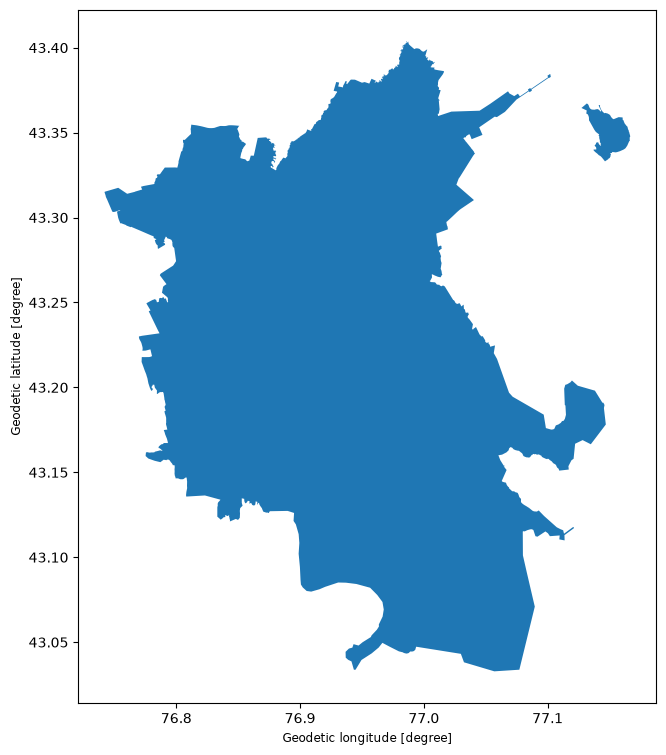

In [2]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

place = "Almaty, Kazakhstan"

almaty = ox.geocode_to_gdf(place) # получаем географическую границу из территории

print(almaty.crs) 
print(almaty.geometry.geom_type.value_counts())
print(almaty.shape)

almaty.plot(figsize=(9,9))
plt.show()

#получили географическую карту Алматы чтобы потом исключать ненужные нам регоины, по типу горы и тд
#мы получили территорию в градусах
#территория так же состоит из нескольких полигонов


In [3]:
# перевод границ в метры

metrics_crs = almaty.estimate_utm_crs()
almaty_m = almaty.to_crs(metrics_crs)

print(almaty_m.crs)

#перевели в метры


EPSG:32643


In [4]:
minX, minY, maxX, maxY = almaty_m.total_bounds

print(f'minX: {minX}')
print(f'minY: {minY}')
print(f'maxX: {maxX}')
print(f'maxY: {maxY}')

#создаются границы для создания прямоугольника который покрывает наш полигон
#а точнее карту Алмайти
#minX/minY - sleva, maxX/maxY - sprava

minX: 641265.5888651052
minY: 4766397.813012956
maxX: 675610.4805611279
maxY: 4807569.400086247


In [5]:
#np.arange() - создает последовательность чисел с определенным шагом

import numpy as np

x_coords = np.arange(minX, maxX, 500)
y_coords = np.arange(minY, maxY, 500)

In [6]:
from itertools import product

coordinates = list(product(x_coords, y_coords))

#Чтобы получить полноценную сетку, нужно составить все комбинации координат X и Y.

print(len(x_coords))
print(len(y_coords))
print(len(coordinates))

#теперь у нас 5727 потенциальных локаций


69
83
5727


In [7]:
from shapely.geometry import Point

# point = Point() # создает точки для каждой пары координат в нашем случае для 5727 пар

all_points_for_almaty = []

for i in range(len(coordinates)):
    
    point = Point(coordinates[i])
    all_points_for_almaty.append(point)


for i in range(5):
    print(all_points_for_almaty[i])

#точки созданы

POINT (641265.5888651052 4766397.813012956)
POINT (641265.5888651052 4766897.813012956)
POINT (641265.5888651052 4767397.813012956)
POINT (641265.5888651052 4767897.813012956)
POINT (641265.5888651052 4768397.813012956)


In [8]:
grid = gpd.GeoDataFrame(
    geometry=all_points_for_almaty,
    crs=almaty_m.crs)

print(grid.shape)
print(grid.crs)

(5727, 1)
EPSG:32643


In [9]:
#нужно сделать grid Almighty

city_geometry = almaty_m.geometry.iloc[0]

#происходит векторный цикл который спрашивает ячейка или point внутри алматы или не?
points_inside_city = grid[grid.geometry.within(city_geometry)]

print(len(points_inside_city))


2822


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

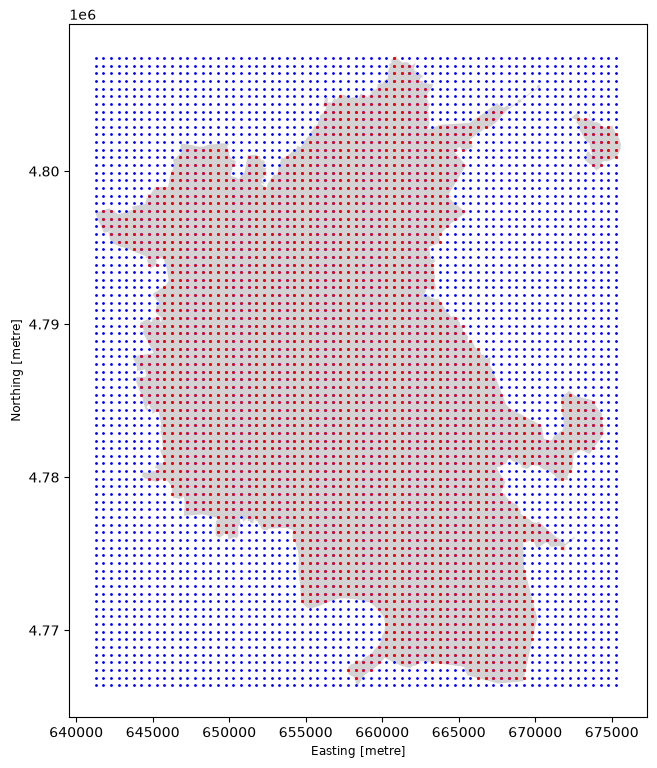

In [10]:
fig, ax = plt.subplots(figsize=(9,9))

almaty_m.plot(ax=ax, color='lightgray', markersize=9) # вся карта алматы

grid.plot(ax=ax, color='blue', markersize=1)

points_inside_city.plot(ax=ax, color='red', markersize=1)

In [11]:
import geopandas as gpd

cafes_points = gpd.read_file(
    "../data/processed/cafes_points.gpkg"
)

print(cafes_points.shape)
print(cafes_points.crs)

points_inside_city.to_file(
    "../data/processed/candidate_locations.gpkg",
    driver="GPKG"
)

print(points_inside_city.crs)
print(cafes_points.crs)

(731, 118)
EPSG:32643
EPSG:32643
EPSG:32643


In [12]:
#добавление функции count_nearby_cafes, чтобы потом я ее просто не копипастил раз за разом

import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))

from src.spatial_features import count_nearby_cafes

candidate = points_inside_city.geometry.iloc[0]

result = count_nearby_cafes(
    candidate,
    cafes_points,
    radius=500
)

print(result)

0


In [13]:
#создаем точки(кафе) в датасет

cafes_counts = []

for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, cafes_points, 500)
    cafes_counts.append(result)


print(len(cafes_counts))
print(cafes_counts[:10])

2822
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [14]:
points_inside_city = points_inside_city.copy()

points_inside_city['cafes_500m'] = cafes_counts

In [15]:
points_inside_city['cafes_500m'].describe()

count    2822.000000
mean        0.813962
std         3.001673
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        42.000000
Name: cafes_500m, dtype: float64

In [16]:
print((points_inside_city['cafes_500m'] == 0).sum())
print((points_inside_city['cafes_500m'] > 0).sum())

2268
554


<Axes: >

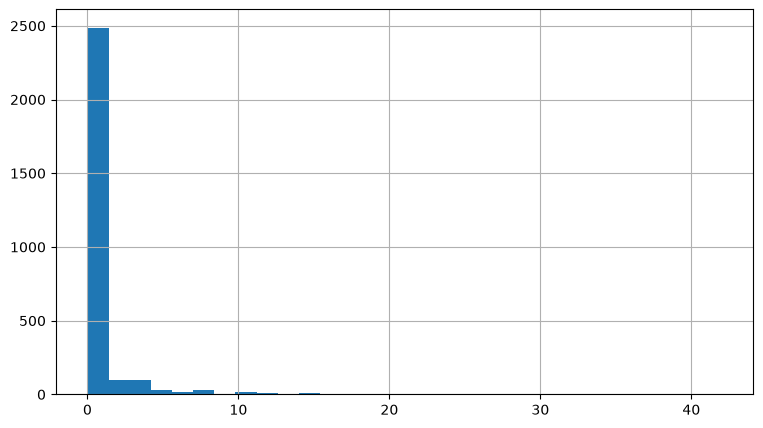

In [17]:
points_inside_city['cafes_500m'].hist(bins=30, figsize=(9,5))

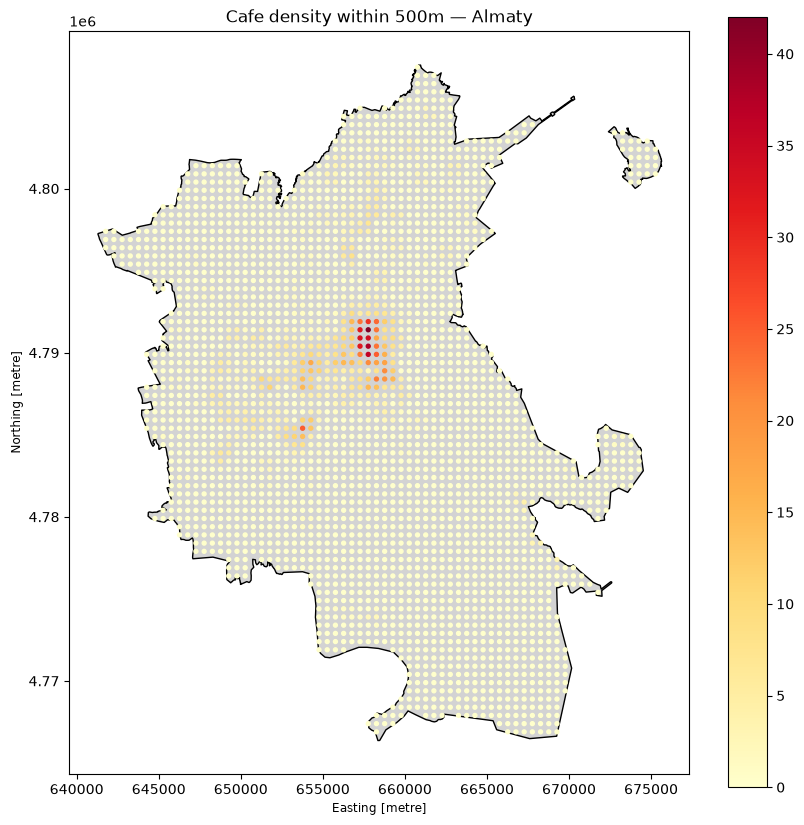

In [18]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,10))

almaty_m.plot(ax=ax, color='lightgray', edgecolor='k')

points_inside_city.plot(
    ax=ax,
    column="cafes_500m",
    cmap="YlOrRd",
    legend=True,
    markersize=8
)

ax.set_title("Cafe density within 500m — Almaty")
plt.show()

In [19]:
radius = [300, 500, 1000]


for radii in radius:

    cafes_counts = []

    for point in points_inside_city.geometry:

        result = count_nearby_cafes(point, cafes_points, radii)
        cafes_counts.append(result)

    points_inside_city[f'cafes_{radii}m'] = cafes_counts

In [20]:
points_inside_city['cafes_300m'].describe()

count    2822.000000
mean        0.282424
std         1.165787
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        19.000000
Name: cafes_300m, dtype: float64

In [21]:
points_inside_city['cafes_500m'].describe()

count    2822.000000
mean        0.813962
std         3.001673
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        42.000000
Name: cafes_500m, dtype: float64

In [22]:
points_inside_city['cafes_1000m'].describe()

count    2822.000000
mean        3.223600
std        10.091989
min         0.000000
25%         0.000000
50%         0.000000
75%         2.000000
max       116.000000
Name: cafes_1000m, dtype: float64

In [23]:
features = ['cafes_300m', 'cafes_500m', 'cafes_1000m']

for item in features:
    print(f'Feature name is {item}')
    print((points_inside_city[item] == 0).sum())
    print((points_inside_city[item] > 0).sum())
    print()

Feature name is cafes_300m
2501
321

Feature name is cafes_500m
2268
554

Feature name is cafes_1000m
1765
1057



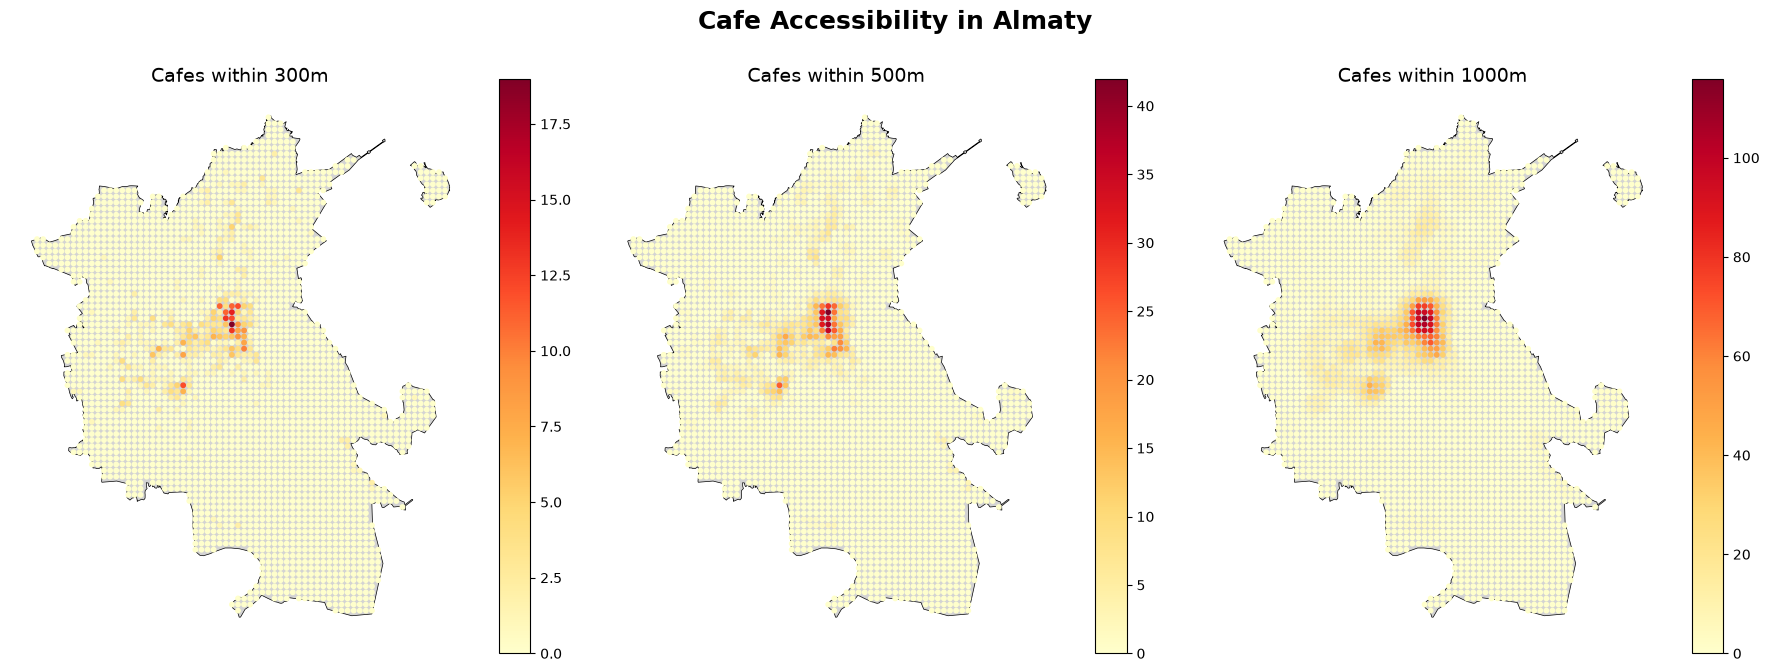

In [24]:
import matplotlib.pyplot as plt

radii = [300, 500, 1000]

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, radius in zip(axes, radii):

    # Граница Алматы
    almaty_m.plot(
        ax=ax,
        color="lightgray",
        edgecolor="black",
        linewidth=0.5
    )

    # Кандидатные точки
    points_inside_city.plot(
        ax=ax,
        column=f"cafes_{radius}m",
        cmap="YlOrRd",
        legend=True,
        markersize=10
    )

    ax.set_title(f"Cafes within {radius}m", fontsize=14)
    ax.set_axis_off()

plt.suptitle(
    "Cafe Accessibility in Almaty",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## Bus Stop Feature Engineering

In [25]:
import osmnx as ox
import geopandas as gpd

place = "Almaty, Kazakhstan"
tags = {"highway" : "bus_stop"}

bus_stops = ox.features_from_place(place,tags)

In [26]:
print(bus_stops.shape)
print(bus_stops.crs)
print(bus_stops.geom_type.value_counts())
print(bus_stops.isnull().sum())


(1996, 55)
epsg:4326
Point      1995
Polygon       1
Name: count, dtype: int64
geometry                            0
highway                             0
name                              189
bench                            1082
bus                               192
name:en                          1279
name:ru                          1595
public_transport                  181
source                           1843
bin                              1231
lit                              1437
shelter                          1004
trolleybus                       1847
name:kk                          1798
departures_board                 1604
int_name                         1957
tactile_paving                   1672
level                            1945
wheelchair                       1764
name:zh                          1994
old_name                         1983
check_date:shelter               1970
covered                          1969
route_ref                        1965
check_dat

In [27]:
print(bus_stops.isna().mean())

geometry                         0.000000
highway                          0.000000
name                             0.094689
bench                            0.542084
bus                              0.096192
name:en                          0.640782
name:ru                          0.799098
public_transport                 0.090681
source                           0.923347
bin                              0.616733
lit                              0.719940
shelter                          0.503006
trolleybus                       0.925351
name:kk                          0.900802
departures_board                 0.803607
int_name                         0.980461
tactile_paving                   0.837675
level                            0.974449
wheelchair                       0.883768
name:zh                          0.998998
old_name                         0.993487
check_date:shelter               0.986974
covered                          0.986473
route_ref                        0

In [28]:
bus_stops.head()

geometry   highway  \
element id                                               
node    442563900  POINT (76.98778 43.35731)  bus_stop   
        442563902  POINT (76.98748 43.35754)  bus_stop   
        442563911  POINT (76.98452 43.34267)  bus_stop   
        442566415  POINT (76.95789 43.32033)  bus_stop   
        442566419  POINT (76.95968 43.32163)  bus_stop   

                                     name bench  bus            name:en  \
element id                                                                
node    442563900                     NaN   NaN  NaN                NaN   
        442563902                     NaN   NaN  NaN                NaN   
        442563911             Рынoк Алтай   NaN  NaN                NaN   
        442566415                 Суюнбая   yes  yes           Suyunbay   
        442566419  Өрт сөндіру бөлімі №11   NaN  yes  Fire station № 11   

                               name:ru public_transport  source  bin  ...  \
element id                                                            ...   
node    442563900                  NaN              NaN     NaN  NaN  ...   
        442563902                  NaN              NaN     NaN  NaN  ...   
        442563911                  NaN              NaN     NaN  NaN  ...   
        442566415              Суюнбая         platform  survey  NaN  ...   
        442566419  Пожарная часть № 11         platform     NaN  NaN  ...   

                  name:signed plot_number name:eb bus_bay addr:district  \
element id                                                                
node    442563900         NaN         NaN     NaN     NaN           NaN   
        442563902         NaN         NaN     NaN     NaN           NaN   
        442563911         NaN         NaN     NaN     NaN           NaN   
        442566415         NaN         NaN     NaN     NaN           NaN   
        442566419         NaN         NaN     NaN     NaN           NaN   

                  backrest seats oneway short_name note  
element id                                               
node    442563900      NaN   NaN    NaN        NaN  NaN  
        442563902      NaN   NaN    NaN        NaN  NaN  
        442563911      NaN   NaN    NaN        NaN  NaN  
        442566415      NaN   NaN    NaN        NaN  NaN  
        442566419      NaN   NaN    NaN        NaN  NaN  

[5 rows x 55 columns]

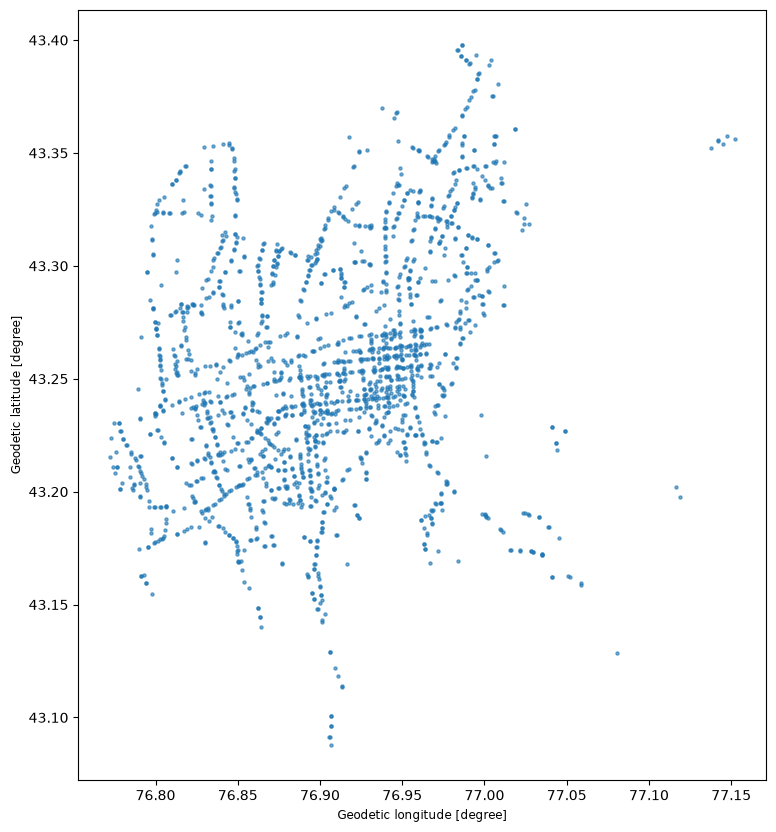

In [29]:
ax = bus_stops.plot(figsize=(10,10), markersize=5, alpha=0.6)

In [30]:
metrics_crs = bus_stops.estimate_utm_crs()

bus_stops_m = bus_stops.to_crs(metrics_crs)

print(bus_stops_m.crs)

EPSG:32643


In [31]:
bus_stops_points = bus_stops_m.copy()

bus_stops_points['geometry'] = bus_stops_points.geometry.representative_point()

In [32]:
print(bus_stops_points.crs)
print(points_inside_city.crs)
print(bus_stops_points.geom_type.value_counts())

EPSG:32643
EPSG:32643
Point    1996
Name: count, dtype: int64


In [33]:

bus_stops500m = []

for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, bus_stops_points, 500)
    bus_stops500m.append(result)


print(len(bus_stops500m))
print(bus_stops500m[:10])

2822
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [34]:
points_inside_city['bus_stops_500m'] = bus_stops500m

print(points_inside_city["bus_stops_500m"].describe())

count    2822.000000
mean        2.181786
std         3.468793
min         0.000000
25%         0.000000
50%         0.000000
75%         4.000000
max        24.000000
Name: bus_stops_500m, dtype: float64


In [35]:
#от каждой точки то считается буффер 500м и потом смотрится попала ли автобусная остановка или нет
# если равна 0 то значит в радиусе 500 м нет автобусной остановки
#то есть точки это потенциальные локации где мы хотим открыть бизнес

print((points_inside_city["bus_stops_500m"] == 0).sum())
print((points_inside_city["bus_stops_500m"] > 0).sum())

1587
1235


In [36]:
print(points_inside_city[
    ['cafes_300m', 'cafes_500m', 'cafes_1000m', 'bus_stops_500m']
].head(20))

     cafes_300m  cafes_500m  cafes_1000m  bus_stops_500m
143           0           0            0               0
144           0           0            0               0
145           0           0            0               0
225           0           0            0               0
226           0           0            0               0
227           0           0            0               0
228           0           0            0               0
307           0           0            0               0
308           0           0            0               0
309           0           0            0               0
310           0           0            0               0
390           0           0            0               0
391           0           0            0               0
392           0           0            0               0
393           0           0            0               0
472           0           0            0               0
473           0           0    

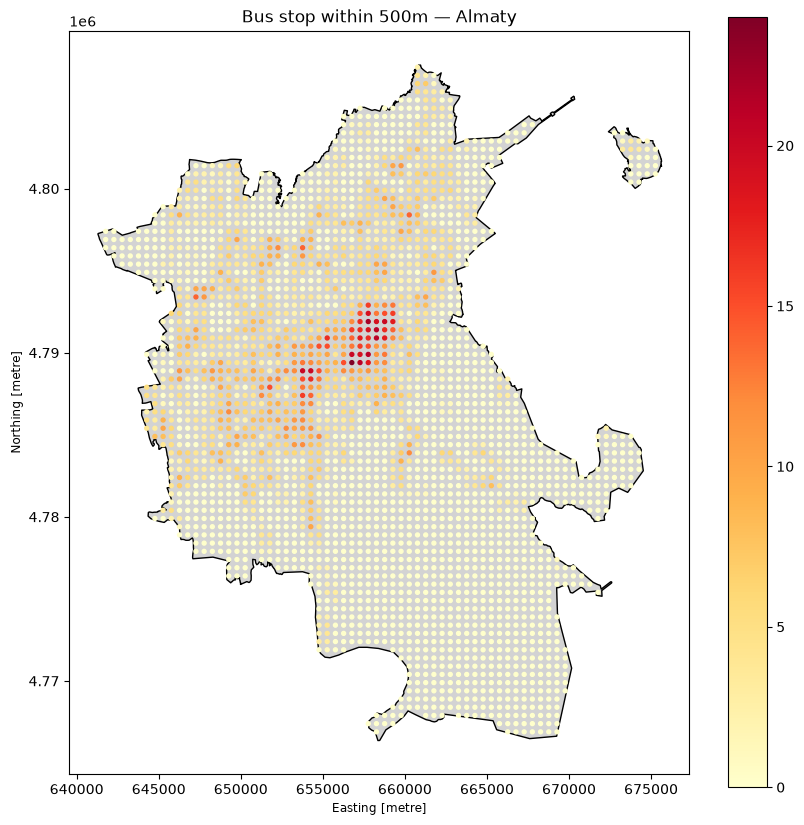

In [37]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,10))

almaty_m.plot(ax=ax, color='lightgray', edgecolor='k')

points_inside_city.plot(
    ax=ax,
    column="bus_stops_500m",
    cmap="YlOrRd",
    legend=True,
    markersize=8
)

ax.set_title("Bus stop within 500m — Almaty")
plt.show()

In [38]:
import geopandas as gpd

residential = gpd.read_file("../data/processed/almaty_residential.gpkg")

print("Shape:", residential.shape)
print("CRS:", residential.crs)
print("\nGeometry types:")
print(residential.geom_type.value_counts())
print("\nBuilding types:")
print(residential["building"].value_counts())
print("\nInvalid geometries:", (~residential.geometry.is_valid).sum())

Shape: (73719, 26)
CRS: EPSG:4326

Geometry types:
MultiPolygon    73719
Name: count, dtype: int64

Building types:
building
house          64574
apartments      7383
detached         958
residential      804
Name: count, dtype: int64

Invalid geometries: 6


In [39]:
metrics_crs = residential.estimate_utm_crs()
residential_m = residential.to_crs(metrics_crs)

print(residential_m.crs)

EPSG:32643


In [40]:
residential_m["geometry"] = residential_m.geometry.make_valid()

print("Invalid:", (~residential_m.geometry.is_valid).sum())
print(residential_m.geom_type.value_counts())

Invalid: 0
MultiPolygon          73713
GeometryCollection        6
Name: count, dtype: int64


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

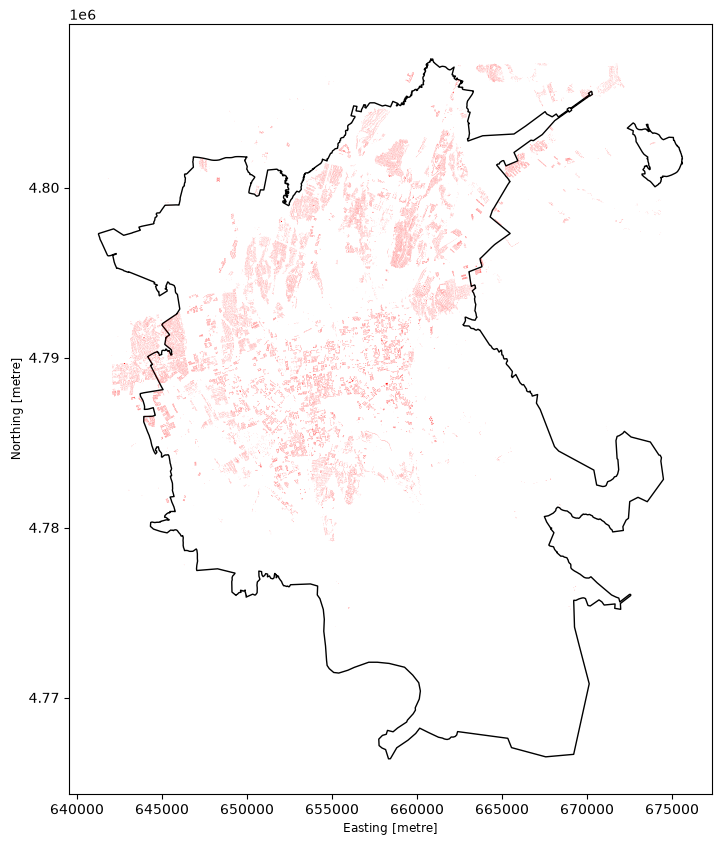

In [41]:
ax = almaty_m.plot(
    figsize=(10, 10),
    facecolor="none",
    edgecolor="black"
)

residential_m.plot(
    ax=ax,
    color="red",
    markersize=1,
    alpha=0.9
)

In [42]:
city_geometry = almaty_m.geometry.iloc[0]

residential_inside = residential_m[
    residential_m.geometry.intersects(city_geometry)
].copy()

In [43]:
print('Before', len(residential_m))
print('After', len(residential_inside))
print('Remove', len(residential_m) - len(residential_inside))
print("Invalid:", (~residential_inside.geometry.is_valid).sum())
print(residential_inside.geom_type.value_counts())

Before 73719
After 63503
Remove 10216
Invalid: 0
MultiPolygon          63497
GeometryCollection        6
Name: count, dtype: int64


In [44]:
residential_points = residential_inside.copy()

residential_points['geometry'] = (
    residential_points.geometry.representative_point()
).copy()

In [45]:
print(residential_points.geom_type.value_counts())
print(residential_points.crs)
print(len(residential_points))

Point    63503
Name: count, dtype: int64
EPSG:32643
63503


In [46]:
test_candidate = points_inside_city.geometry.iloc[0]

print(count_nearby_cafes(test_candidate, residential_points, radius=500))

0


In [47]:
residential_buildings_500m = []

for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, residential_points, radius=500)
    residential_buildings_500m.append(result)

print(len(residential_buildings_500m))

points_inside_city['residential_buildings_500m'] = residential_buildings_500m

print(points_inside_city['residential_buildings_500m'].describe())
print('First 10',residential_buildings_500m[:10])
print('Zero locations', residential_buildings_500m.count(0))


#мы проходимся по всем потенциальным лоакациям для открытия бизнеса и смотрим сколько жилых зданий распологнается вблизи 500м

2822
count    2822.000000
mean       69.811481
std       140.156397
min         0.000000
25%         0.000000
50%         1.000000
75%        68.000000
max       885.000000
Name: residential_buildings_500m, dtype: float64
First 10 [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
Zero locations 1379


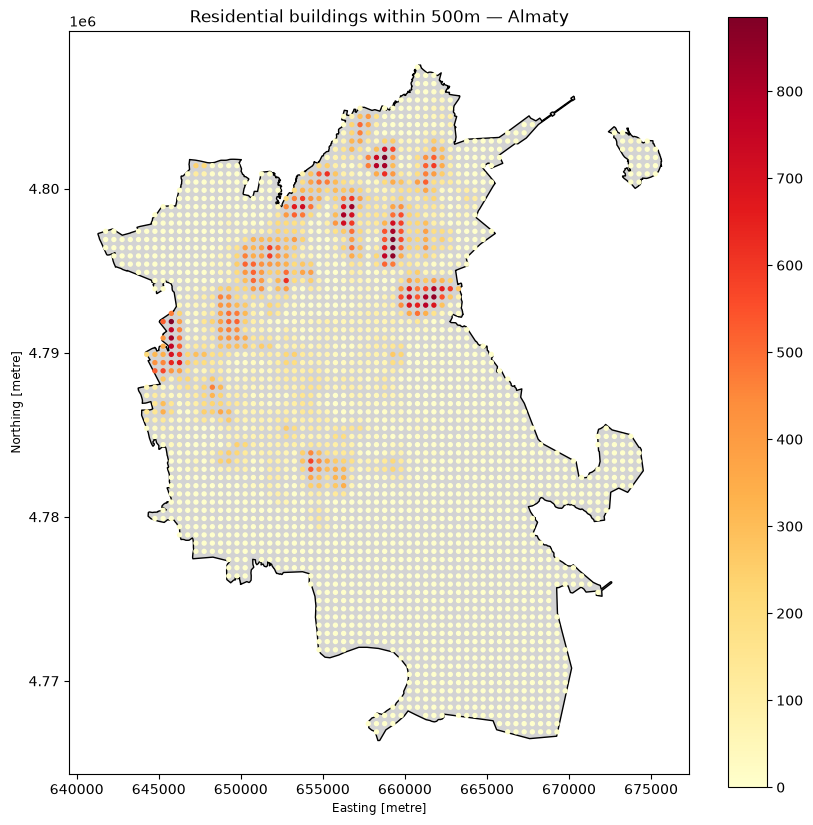

In [48]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10,10))

almaty_m.plot(ax=ax, color='lightgray', edgecolor='k')

points_inside_city.plot(
    ax=ax,
    column='residential_buildings_500m',
    cmap="YlOrRd",
    legend=True,
    markersize=8
)

ax.set_title("Residential buildings within 500m — Almaty")
plt.show()

In [49]:
residential_points['building'].value_counts()

building
house          55110
apartments      7149
residential      672
detached         572
Name: count, dtype: int64

In [50]:
houses = residential_points[
    residential_points['building'].isin(['house', 'detached'])
].copy()

apartments = residential_points[
    residential_points['building'] == 'apartments'
].copy()

residential_unknown = residential_points[
    residential_points['building'] == 'residential'
].copy()

In [51]:
print(len(houses))
print(len(apartments))
print(len(residential_unknown))

55682
7149
672


In [52]:
building_types = {
    'houses' : houses,
    'apartments': apartments,
    'residential_unknown': residential_unknown
}

# residential_buildings_500m = []

# for point in points_inside_city.geometry:
#     result = count_nearby_cafes(point, residential_points, radius=500)
#     residential_buildings_500m.append(result)


houses_500m = []
apartments_500m = []
residential_unknown_500m = []


for key, value in building_types.items():
    for point in points_inside_city.geometry:
        if key == 'houses':
            result = count_nearby_cafes(point, value, radius=500)
            houses_500m.append(result)
        elif key == 'apartments':
            result = count_nearby_cafes(point, value, radius=500)
            apartments_500m.append(result)
        else:
            result = count_nearby_cafes(point, value, radius=500)
            residential_unknown_500m.append(result)


#когда мы проходимся циклом мы получаем в каждой ячейке массива одно число, в нашем случае сколько домов рядом в радиусе 500 м и тд

        


In [53]:
print(len(houses_500m) + len(apartments_500m) + len(residential_unknown_500m))

print(len(residential_buildings_500m))
print('Zero locations', residential_buildings_500m.count(0))
print('Zero houses', houses_500m.count(0))
print('Zero apartments', apartments_500m.count(0))
print('Zero residential_unkown', residential_unknown_500m.count(0))

8466
2822
Zero locations 1379
Zero houses 1562
Zero apartments 2018
Zero residential_unkown 2597


In [54]:
points_inside_city["houses_500m"] = houses_500m
points_inside_city["apartments_500m"] = apartments_500m
points_inside_city["residential_unknown_500m"] = residential_unknown_500m

In [55]:
total = (
    points_inside_city["houses_500m"]
    + points_inside_city["apartments_500m"]
    + points_inside_city["residential_unknown_500m"]
)

print(
    (total == points_inside_city["residential_buildings_500m"]).all()
)
#проверяю правильно ли все выполнилось

True


In [56]:
columns = [
    "houses_500m",
    "apartments_500m",
    "residential_unknown_500m",
    "residential_buildings_500m"
]

points_inside_city[columns].describe()


,houses_500m,apartments_500m,residential_unknown_500m,residential_buildings_500m
count,2822.000000,2822.000000,2822.000000,2822.000000
mean,61.173281,7.898653,0.739546,69.811481
std,139.124729,19.349113,5.133992,140.156397
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,1.000000
75%,35.000000,2.000000,0.000000,68.000000
max,885.000000,147.000000,101.000000,885.000000


- Первое наблюдение: частных домов в окрестностях кандидатных точек в среднем значительно больше, чем многоквартирных.
- Второе наблюдение: медиана частных и многоквартирных домов равна нулю. Это говорит о том, что как минимум половина наших кандидатных точек не имеет соответствующих зданий в радиусе 500 м.
- Третье наблюдение: максимальное количество частных домов — 885. Это высокое значение, но не обязательно ошибка. Например, оно может встречаться в районах с плотной малоэтажной застройкой.

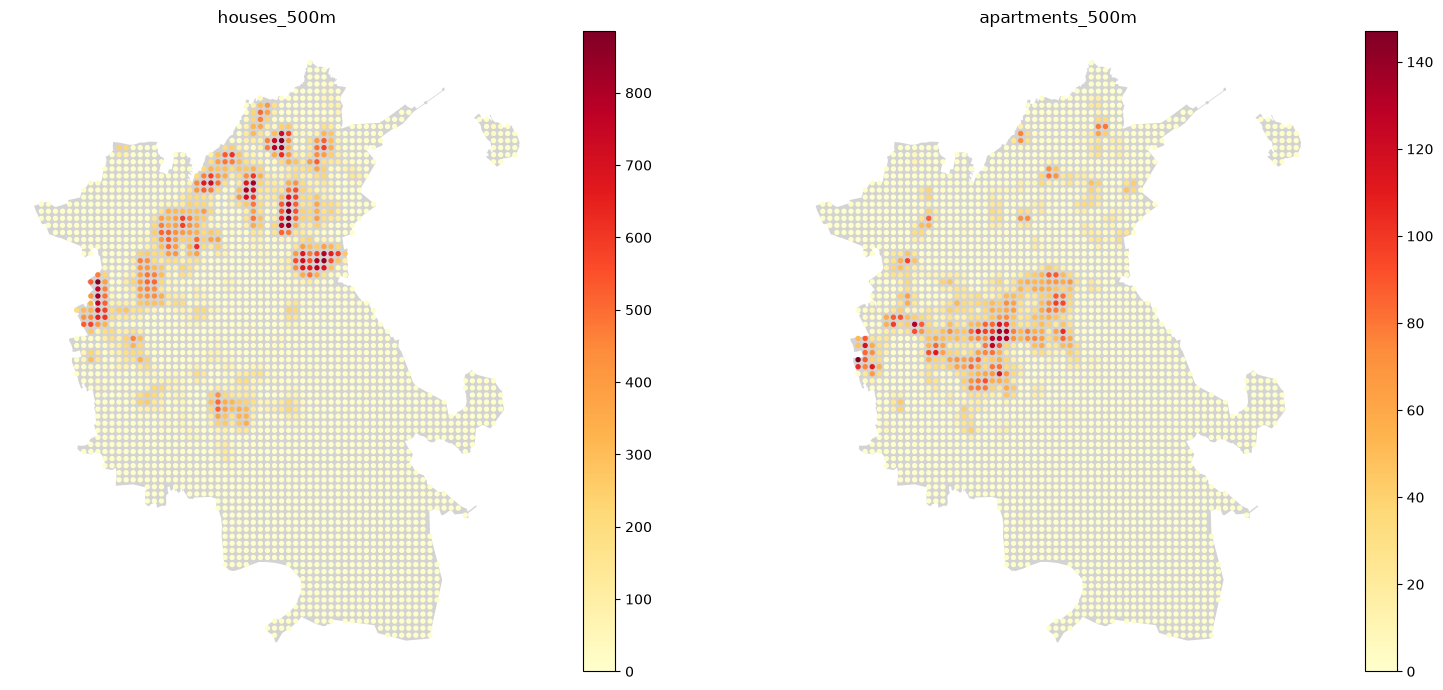

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, feature in zip(
    axes,
    ["houses_500m", "apartments_500m"]
):
    almaty_m.plot(ax=ax, color="lightgray")

    points_inside_city.plot(
        ax=ax,
        column=feature,
        cmap="YlOrRd",
        markersize=8,
        legend=True
    )

    ax.set_title(feature)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [58]:
points_inside_city.to_file(
    "../data/processed/candidate_locations.gpkg",
    driver="GPKG"
)

In [59]:
import geopandas as gpd

offices = gpd.read_file(
    '/Users/david/Desktop/business-location-ai/business-location-ai/data/processed/almaty_offices.gpkg'
)

print(offices.shape)
print(offices.crs)
print(offices.geom_type.value_counts())

(163, 26)
EPSG:4326
MultiPolygon    163
Name: count, dtype: int64


In [60]:
offices_m = offices.to_crs(points_inside_city.crs) # приводим к одной системе измерения

print(f'Ivalid geometries: {(~offices_m.geometry.is_valid).sum()}')

offices_m['geometry'] = offices_m.geometry.make_valid()

city_geometry = almaty_m.geometry.iloc[0]

offices_inside = offices_m[
    offices_m.geometry.intersects(city_geometry)
].copy()

print("Before:", len(offices_m))
print("After:", len(offices_inside))



Ivalid geometries: 0
Before: 163
After: 155


In [61]:
offices_pois = gpd.read_file(
    '/Users/david/Desktop/business-location-ai/business-location-ai/data/processed/almaty_office_pois.gpkg'
)

print("Total:", len(offices_pois))
print(offices_pois["office"].value_counts().head(15))

print(offices_pois.shape)
print(offices_pois.crs)
print(offices_pois.geom_type.value_counts())

#разница office and office_pois в том что первое отвечает за здание а второе за именно офис определенной компании

Total: 113
office
government                 36
yes                        14
diplomatic                 11
company                    10
security                   10
research                    8
telecommunication           6
charity                     3
religion                    2
it                          2
foundation                  1
publisher                   1
association                 1
educational_institution     1
advertising_agency          1
Name: count, dtype: int64
(113, 26)
EPSG:4326
MultiPolygon    113
Name: count, dtype: int64


In [62]:
common_ids = set(offices['osm_id']) & set(offices_pois['osm_id'])

print("Common OSM IDs:", len(common_ids))

Common OSM IDs: 1


In [63]:
print(offices[["osm_id", "osm_way_id", "building", "office"]].head())
print(offices_pois[["osm_id", "osm_way_id", "building", "office"]].head())

     osm_id osm_way_id building office
0  19914587        NaN   office    NaN
1  21030106        NaN   office    NaN
2       NaN   27064532   office    NaN
3       NaN   27082561   office    NaN
4       NaN   27107722   office    NaN
     osm_id osm_way_id building      office
0   2874807        NaN      yes  government
1  18268164        NaN      yes  foundation
2  21435804        NaN      yes  government
3       NaN   27054580      yes  government
4       NaN   27054597      yes    research


In [64]:
common_osm = set(offices['osm_id'].dropna()) & set(offices_pois['osm_id'].dropna())

common_way =  set(offices["osm_way_id"].dropna()) & set(offices_pois["osm_way_id"].dropna())


print("Common osm_id:", len(common_osm))
print("Common osm_way_id:", len(common_way))

Common osm_id: 0
Common osm_way_id: 4


In [65]:
import pandas as pd

office_objects = pd.concat(
    [offices, offices_pois],
    ignore_index=True
)

print("Before:", len(office_objects))

Before: 276


In [66]:
office_objects['object_id'] = (
    office_objects['osm_way_id'].fillna('id:' + office_objects['osm_id'].fillna(''))
)

office_objects = office_objects.drop_duplicates(subset='object_id')


print("After:", len(office_objects))

After: 272


In [67]:
office_objects_m = office_objects.to_crs(points_inside_city.crs)

office_objects_m["geometry"] = (
    office_objects_m.geometry.make_valid()
)

office_objects_inside = office_objects_m[
    office_objects_m.geometry.intersects(city_geometry)
].copy()

print("Before:", len(office_objects_m))
print("Inside Almaty:", len(office_objects_inside))

Before: 272
Inside Almaty: 262


In [68]:
office_points = office_objects_inside.copy()

office_points['geometry'] = office_points.geometry.representative_point()

print(office_points.geom_type.value_counts())
print(office_points.crs)

Point    262
Name: count, dtype: int64
EPSG:32643


In [69]:
office_objects_500m = []

for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, office_points, 500)
    office_objects_500m.append(result)


print(len(office_objects_500m))
print(office_objects_500m[:10])

2822
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]


In [70]:
points_inside_city['office_objects_500m'] = office_objects_500m

print(points_inside_city['office_objects_500m'].describe())

count    2822.000000
mean        0.289865
std         1.156473
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        18.000000
Name: office_objects_500m, dtype: float64


In [71]:
office_osm_points = gpd.read_file(
    "/Users/david/Desktop/business-location-ai/business-location-ai/data/processed/almaty_office_points.gpkg"
)

print(office_osm_points.shape)
print(office_osm_points.crs)
print(office_osm_points["other_tags"].head())

(391, 11)
EPSG:4326
0                               "office"=>"government"
1           "government"=>"tax","office"=>"government"
2    "country"=>"MN","diplomatic"=>"embassy","embas...
3                                      "office"=>"yes"
4                                      "office"=>"yes"
Name: other_tags, dtype: str


In [72]:
office_osm_points_m = office_osm_points.to_crs(
    points_inside_city.crs
)

#within(), потому что объекты уже представлены точками.
office_osm_points_inside = office_osm_points_m[
    office_osm_points_m.geometry.within(city_geometry)
].copy()

print("Before:", len(office_osm_points_m))
print("Inside Almaty:", len(office_osm_points_inside))

Before: 391
Inside Almaty: 379


In [73]:
office_osm_points_inside["office_type"] = (
    office_osm_points_inside["other_tags"]
    .str.extract(r'"office"=>"([^"]+)"')
)

print(
    office_osm_points_inside["office_type"]
    .value_counts()
)


office_type
company                    103
telecommunication           56
lawyer                      42
government                  27
notary                      26
diplomatic                  15
financial_advisor           15
insurance                   13
educational_institution     12
yes                          9
estate_agent                 8
coworking                    8
ngo                          6
it                           4
advertising_agency           4
logistics                    4
financial                    4
guide                        4
research                     3
energy_supplier              2
engineer                     2
association                  1
consulting                   1
travel_agent                 1
accountant                   1
architect                    1
foundation                   1
geodesist                    1
translator                   1
security                     1
charity                      1
graphic_design             

In [74]:
joined = gpd.sjoin(
    office_osm_points_inside,
    office_objects_inside[['geometry']],
    how='left',
    predicate='within' # проверяет находится ли точка внутри полигона
)

points_in_polygons = joined[
    joined["index_right"].notna() #index_right показывает какой полигон совпал с точкой
]

print("Matches:", len(points_in_polygons))
print(
    "Unique matched points:",
    points_in_polygons.index.nunique()
)



Matches: 41
Unique matched points: 41


In [75]:
points_inside_city.rename(
    columns={'office_objects_500m':'office_polygons_500m'}, inplace=True
)

/var/folders/hs/hj4pbp390fl8bl6m_js8rq8c0000gn/T/ipykernel_60183/3859078425.py:1: Pandas4Warning: The inplace keyword in GeoDataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  points_inside_city.rename(


In [76]:
offices_pois_500m = []


for point in points_inside_city.geometry:
    result = count_nearby_cafes(point, office_osm_points_inside, radius=500)
    offices_pois_500m.append(result)

print(len(offices_pois_500m))
print(offices_pois_500m[:10])

print(points_inside_city.crs)
print(office_osm_points_inside.crs)
print(len(office_osm_points_inside))

2822
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0)]
EPSG:32643
EPSG:32643
379


In [77]:
points_inside_city['offices_pois_500m'] = offices_pois_500m

print(points_inside_city['offices_pois_500m'].describe())

count    2822.000000
mean        0.411765
std         1.442448
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        18.000000
Name: offices_pois_500m, dtype: float64


In [78]:
columns = [
    "office_polygons_500m",
    "offices_pois_500m"
]

print(points_inside_city[columns].corr())

print(
    "Locations with at least one office object:",
    (
        (points_inside_city["office_polygons_500m"] > 0) |
        (points_inside_city["offices_pois_500m"] > 0)
    ).sum()
)

                      office_polygons_500m  offices_pois_500m
office_polygons_500m              1.000000           0.677491
offices_pois_500m                 0.677491           1.000000
Locations with at least one office object: 498


Корреляция 0.677 означает, что офисные полигоны и точечные POI часто встречаются в одних районах, но не полностью повторяют друг друга. Пока оставляем оба признака.

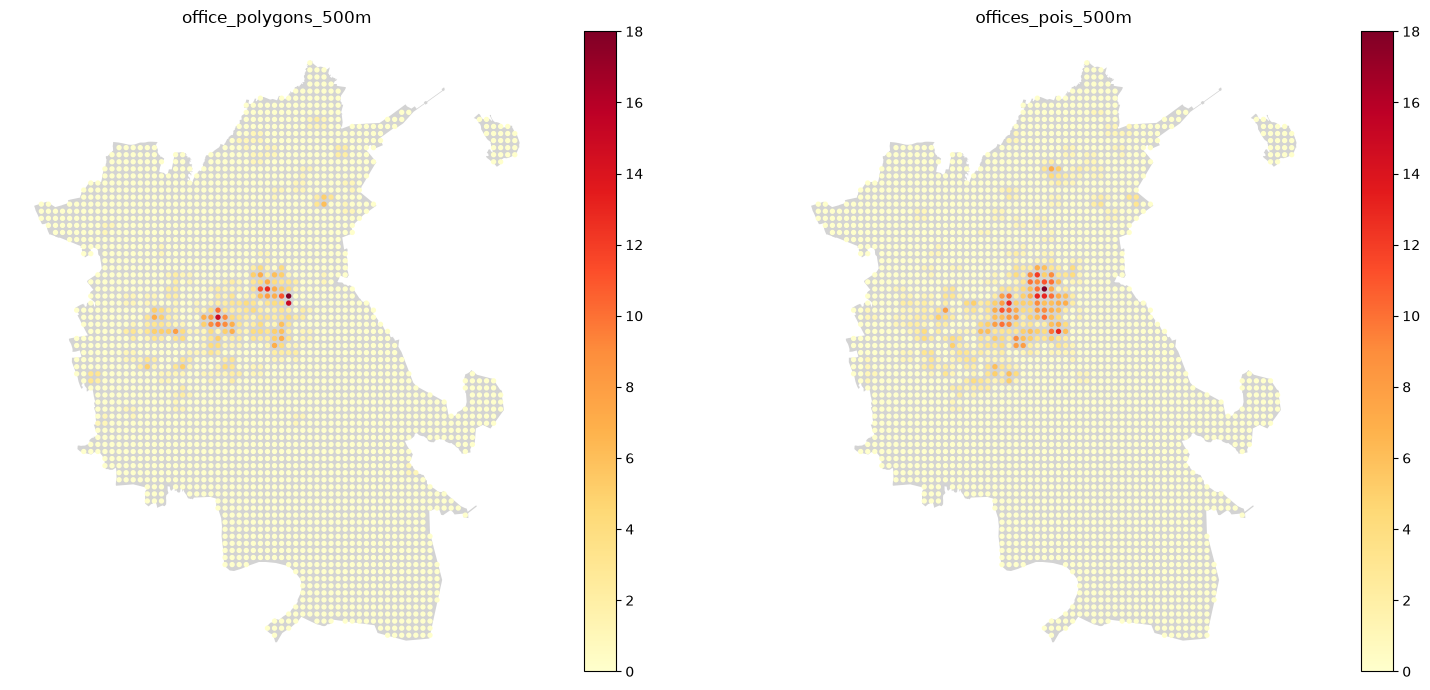

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, feature in zip(
    axes,
    ["office_polygons_500m", "offices_pois_500m"]
):
    almaty_m.plot(ax=ax, color="lightgray")

    points_inside_city.plot(
        ax=ax,
        column=feature,
        cmap="YlOrRd",
        markersize=8,
        legend=True
    )

    ax.set_title(feature)
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [80]:
points_inside_city.to_file(
    "../data/processed/candidate_locations.gpkg",
    driver="GPKG"
)

In [81]:
print(points_inside_city.shape)
print(points_inside_city.columns.tolist())
print(points_inside_city.crs)

(2822, 11)
['geometry', 'cafes_500m', 'cafes_300m', 'cafes_1000m', 'bus_stops_500m', 'residential_buildings_500m', 'houses_500m', 'apartments_500m', 'residential_unknown_500m', 'office_polygons_500m', 'offices_pois_500m']
EPSG:32643


In [83]:
universities = gpd.read_file(
    "/Users/david/Desktop/business-location-ai/business-location-ai/data/processed/almaty_universities_polygons.gpkg"
)

print("Количество:", len(universities))
print("CRS:", universities.crs)
print(universities.geom_type.value_counts())
print(universities[["name", "amenity", "building"]].head(10))

Количество: 33
CRS: EPSG:4326
MultiPolygon    33
Name: count, dtype: int64
                                                name     amenity    building
0           Қазақстан-Британ Техникалық Университеті  university         yes
1                                        Нұр-Мубәрак  university  university
2                                            ҚазБСҚА  university         NaN
3  С.Ж.Аспандияров атындағы Қазақ ұлттық медецина...  university         NaN
4                         Химический Факультет КазНУ  university  university
5                                             Нархоз  university  university
6        Алматинский Финансово-Экономический Колледж  university  university
7                                                ЕТУ  university  university
8                                               АГТУ  university  university
9                Әл-Фараби атындағы ҚазҰУ технопаркі  university  university


In [84]:
universities_points = gpd.read_file(
    "/Users/david/Desktop/business-location-ai/business-location-ai/data/processed/almaty_universities_points.gpkg"
)

print("Количество точек:", len(universities_points))
print("CRS:", universities_points.crs)
print("Типы геометрий:")
print(universities_points.geom_type.value_counts())

print("\nНазвания университетов:")
print(universities_points[["name", "other_tags"]].head(15))

Количество точек: 17
CRS: EPSG:4326
Типы геометрий:
Point    17
Name: count, dtype: int64

Названия университетов:
                                                 name  \
0   Казахский университет международных отношений ...   
1   Қазақстан менеджмент, экономика және болжау ин...   
2    Мұхаметжан Тынышбайұлы атындағы ALT Университеті   
3                                     ҚазҰУ Ректораты   
4                                      Интернет центр   
5                                                 АТУ   
6                                                 UIB   
7        А. Х. Марғұлан атындағы археология Институты   
8       А. Байтұрсынұлы атындағы тіл білімі Институты   
9        Философия, саясаттану және дінтану Институты   
10  Ш. Уәлиханов атындағы Тарих және Этнология Инс...   
11                                       Ғылым Ордасы   
12                        Институт судебных экспертиз   
13  Казахский НИИ экономики агропромышленного комп...   
14  Казахстанско-Российский Вы

In [ ]:
universities_poly_m = universities.to_crs(points_inside_city.crs)
universities_points_m = universities_points.to_crs(points_inside_city.crs)

matches = gpd.sjoin(
    universities_points_m,
    universities_poly_m[['name', 'geometry']],
    how='left',
    predicate="within",
    lsuffix="point",
    rsuffix="polygon"
)

print("Всего исходных точек:", len(universities_points_m))

print("Уникальных точек внутри полигонов:",matches.loc[matches['index_polygon'].notna()].index.nunique())

print("\nСовпадения:")
display(
    matches.loc[
        matches["index_polygon"].notna(),
        ["name_point", "name_polygon"]
    ]
)

'''
ищем уникальные уники чтобы не завысить данные, то есть бывает два здания одного филила в одном полигоне
поэтому их нужно соединять воедино
display() отображает DataFrame как форматированную таблицу с колонками, строками и визуальным оформлением.
nunique - num of unique el, unique - indx of unique numbers
'''


Всего исходных точек: 17
Уникальных точек внутри полигонов: 3

Совпадения:


,name_point,name_polygon
2,Мұхаметжан Тынышбайұлы атындағы ALT Университеті,Мұхаметжан Тынышбайұлы атындағы ALT Университеті
3,ҚазҰУ Ректораты,Әл-Фараби атындағы Қазақ Ұлттық Университеті
4,Интернет центр,Әл-Фараби атындағы Қазақ Ұлттық Университеті


In [88]:
outside_indices = matches.loc[
    matches['index_polygon'].isna()
].index.unique()

universities_points_outside = universities_points_m.loc[
    outside_indices
].copy()

print("Точек вне полигонов:", len(universities_points_outside))

display(
    universities_points_outside[["name", "geometry"]]
)

Точек вне полигонов: 14


,name,geometry
0,Казахский университет международных отношений ...,POINT (657150.148 4790810.388)
1,"Қазақстан менеджмент, экономика және болжау ин...",POINT (658770.228 4789693.635)
5,АТУ,POINT (650954.507 4790253.644)
6,UIB,POINT (658273.583 4789552.994)
7,А. Х. Марғұлан атындағы археология Институты,POINT (658555.935 4790029.145)
8,А. Байтұрсынұлы атындағы тіл білімі Институты,POINT (658635.467 4789926.253)
9,"Философия, саясаттану және дінтану Институты",POINT (658504.89 4789910.913)
10,Ш. Уәлиханов атындағы Тарих және Этнология Инс...,POINT (658623.104 4790019.381)
11,Ғылым Ордасы,POINT (658493.574 4790003.832)
12,Институт судебных экспертиз,POINT (659032.65 4792031.574)


In [91]:
display(
    universities[
        ["name", "amenity", "building"]
    ]
)

,name,amenity,building
0,Қазақстан-Британ Техникалық Университеті,university,yes
1,Нұр-Мубәрак,university,university
2,ҚазБСҚА,university,NaN
3,С.Ж.Аспандияров атындағы Қазақ ұлттық медецина...,university,NaN
4,Химический Факультет КазНУ,university,university
5,Нархоз,university,university
6,Алматинский Финансово-Экономический Колледж,university,university
7,ЕТУ,university,university
8,АГТУ,university,university
9,Әл-Фараби атындағы ҚазҰУ технопаркі,university,university


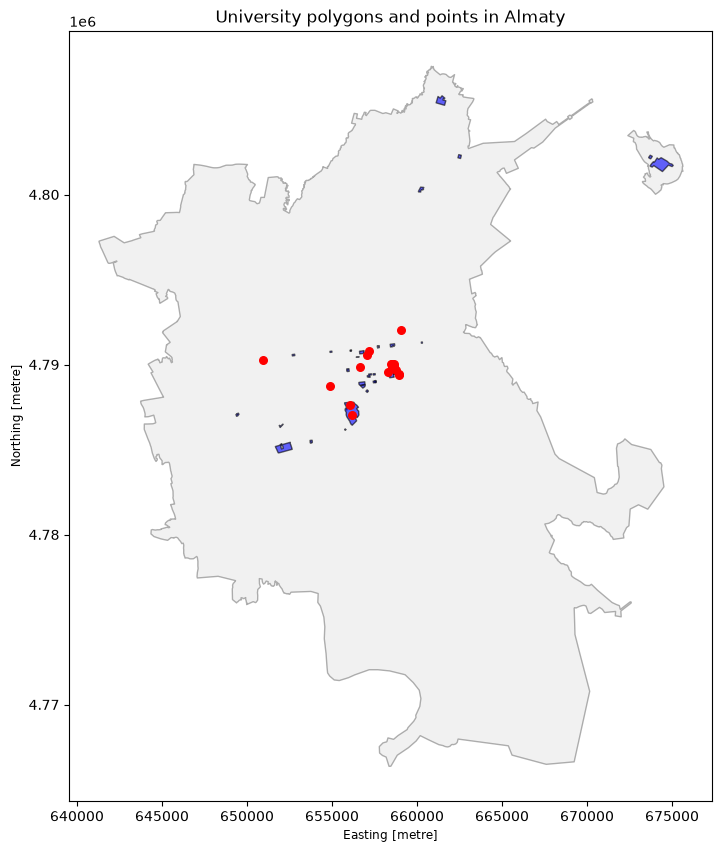

In [93]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))

# Граница Алматы
almaty_m.plot(
    ax=ax,
    facecolor="lightgray",
    edgecolor="black",
    alpha=0.3
)

# Университетские полигоны
universities_poly_m.plot(
    ax=ax,
    color="blue",
    alpha=0.6,
    edgecolor="black"
)

# Университетские точки
universities_points_m.plot(
    ax=ax,
    color="red",
    markersize=30
)

ax.set_title("University polygons and points in Almaty")
plt.show()

In [94]:
nested = gpd.sjoin(
    universities_poly_m,
    universities_poly_m[["name", "geometry"]],
    predicate="within",
    lsuffix="inner",
    rsuffix="outer"
)

# Исключаем совпадение объекта с самим собой
nested = nested[
    nested.index != nested["index_outer"]
]

display(nested[["name_inner", "name_outer"]])

,name_inner,name_outer
9,Әл-Фараби атындағы ҚазҰУ технопаркі,Әл-Фараби атындағы Қазақ Ұлттық Университеті
13,Тұран Университеті,Тұран Университеті


In [95]:
nested_areas = nested.copy()

nested_areas["inner_area_m2"] = nested_areas.geometry.area

nested_areas["outer_area_m2"] = nested_areas["index_outer"].map(
    universities_poly_m.geometry.area
)

nested_areas["area_ratio"] = (
    nested_areas["inner_area_m2"] /
    nested_areas["outer_area_m2"]
)

display(
    nested_areas[
        [
            "name_inner",
            "name_outer",
            "inner_area_m2",
            "outer_area_m2",
            "area_ratio"
        ]
    ]
)

,name_inner,name_outer,inner_area_m2,outer_area_m2,area_ratio
9,Әл-Фараби атындағы ҚазҰУ технопаркі,Әл-Фараби атындағы Қазақ Ұлттық Университеті,630.385217,752102.435621,0.000838
13,Тұран Университеті,Тұран Университеті,2884.314057,18289.953739,0.157699


In [ ]:
'''
Для первой версии CoffeeSpot AI будем считать университетские локации (кампусы), а не количество отдельных зданий.
'''

nested_indices = nested.index.unique() # индексы вложенныъ полигонов

universities_campuses = universities_poly_m.drop(
    index=nested_indices
).copy()

print("Исходных полигонов:", len(universities_poly_m))
print("Вложенных полигонов:", len(nested_indices))
print("Осталось:", len(universities_campuses))

Исходных полигонов: 33
Вложенных полигонов: 2
Осталось: 31


In [100]:
# теперь ищем не тех кто внутри полигона, а тех кто пересекает

overlaps = gpd.sjoin(
    universities_campuses,
    universities_campuses[['name', 'geometry']],
    predicate='overlaps',
    lsuffix='left',
    rsuffix='right'
)

display(overlaps[['name_left', 'name_right']])
print("Количество пересечений:", len(overlaps))


,name_left,name_right


Количество пересечений: 0


In [102]:
duplicates = universities_campuses[
    universities_campuses['name'].notna() & universities_campuses['name'].duplicated(keep=False)
]#notna - убирает все nan, duplicated where keep=False - отмечает тру для всех повторов


display(duplicates[["name", "geometry"]])
print("Объектов с повторяющимися названиями:", len(duplicates))


,name,geometry
15,Қазақ ұлттық аграрлық зерттеу университеті,"MULTIPOLYGON (((657328.793 4789392.977, 657322..."
29,Қазақ ұлттық аграрлық зерттеу университеті,"MULTIPOLYGON (((657539.251 4789467.173, 657547..."


Объектов с повторяющимися названиями: 2


In [103]:
poly_15 = universities_campuses.loc[15, 'geometry']
poly_29 = universities_campuses.loc[29, 'geometry']

distance = poly_15.distance(poly_29)

print(f"Расстояние между полигонами: {distance:.2f} м")

Расстояние между полигонами: 97.15 м


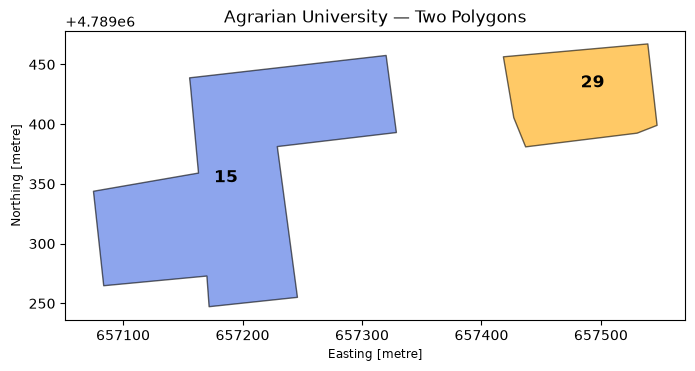

In [104]:
fig, ax = plt.subplots(figsize=(8, 8))

universities_campuses.loc[[15, 29]].plot(
    ax=ax,
    color=["royalblue", "orange"],
    edgecolor="black",
    alpha=0.6
)

for idx in [15, 29]:
    point = universities_campuses.loc[idx, "geometry"].representative_point()

    ax.annotate(
        str(idx),
        (point.x, point.y),
        fontsize=12,
        fontweight="bold"
    )

ax.set_title("Agrarian University — Two Polygons")
ax.set_aspect("equal")
plt.show()

In [ ]:
#так как эти два полигона относятя к одному унику и находятся всего на расстоянии менее 100м, их надо соединить в один уник
'''
unary_union создаёт объединённую геометрию. Поскольку полигоны не соприкасаются, результат может быть MultiPolygon — это нормально.
'''
from shapely.ops import unary_union

agrarian_campus = unary_union(
    universities_campuses.loc[[15,29], 'geometry'].tolist()
)

In [106]:
universities_campuses = universities_campuses.copy()

universities_campuses['campus_id'] = (
    universities_campuses.index.astype('str')
)

universities_campuses.loc[[15,29], 'campus_id'] = 'agrarian_university'

print("Полигонов:", len(universities_campuses))
print("Уникальных campus_id:", universities_campuses["campus_id"].nunique())

Полигонов: 31
Уникальных campus_id: 30


In [ ]:
university_points_work = universities_points_outside.copy()

university_points_work['campus_id'] = (
    'point_' + university_points_work.index.astype(str) #делаем индексы для наших точек которые не попали в полигон
)


university_points_work["source_type"] = "point"
universities_campuses["source_type"] = "polygon"

#source_type — наша собственная метка, которая показывает, из какого рабочего слоя пришёл объект.

print("Полигонов:", len(universities_campuses))
print("Точек:", len(university_points_work))

Полигонов: 31
Точек: 14


In [108]:
import pandas as pd

universities_all = gpd.GeoDataFrame(
    pd.concat(
        [
            universities_campuses,
            university_points_work
        ],
        ignore_index=True
    ),
    geometry='geometry',
    crs='EPSG:32643'
)

print("Всего объектов:", len(universities_all))
print("Уникальных campus_id:", universities_all["campus_id"].nunique())
print(universities_all.geom_type.value_counts())

Всего объектов: 45
Уникальных campus_id: 44
MultiPolygon    31
Point           14
Name: count, dtype: int64


In [112]:
#чуть меняю функцию count_nearby_cafes теперь нужно считать уникальные campus id

def count_nearby_cafes(candidate, cafes, radius=500):
    buffer_cafe = candidate.buffer(radius)
    return cafes.geometry.intersects(buffer_cafe).sum()

def count_nearby_campuses(point, campuses,radius=500):
    buffer_point = point.buffer(radius)

    nearby = campuses[
        campuses.geometry.intersects(buffer_point)
    ]

    return nearby['campus_id'].nunique()



In [116]:
test_point = points_inside_city.geometry.iloc[0]

res = count_nearby_campuses(test_point, universities_all, radius=500)

print("Университетских локаций поблизости:", res)



Университетских локаций поблизости: 0


In [117]:
next_test_point = universities_campuses.geometry.iloc[0].representative_point()

res = count_nearby_campuses(
    next_test_point,
    universities_all,
    radius=500
)

print("Университетских локаций поблизости:", res)

Университетских локаций поблизости: 1


In [118]:
universities_500m = []

for point in points_inside_city.geometry:
    result = count_nearby_campuses(point, universities_all, 500)
    universities_500m.append(result)


print(len(universities_500m))
print(universities_500m[:10])

2822
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [119]:
points_inside_city['universities_500m'] = universities_500m

print(points_inside_city["universities_500m"].describe())

print(
    "Точек рядом с университетами:",
    (points_inside_city["universities_500m"] > 0).sum()
)

print(
    "Максимум университетских локаций:",
    points_inside_city["universities_500m"].max()
)

count    2822.000000
mean        0.071935
std         0.422849
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         9.000000
Name: universities_500m, dtype: float64
Точек рядом с университетами: 132
Максимум университетских локаций: 9


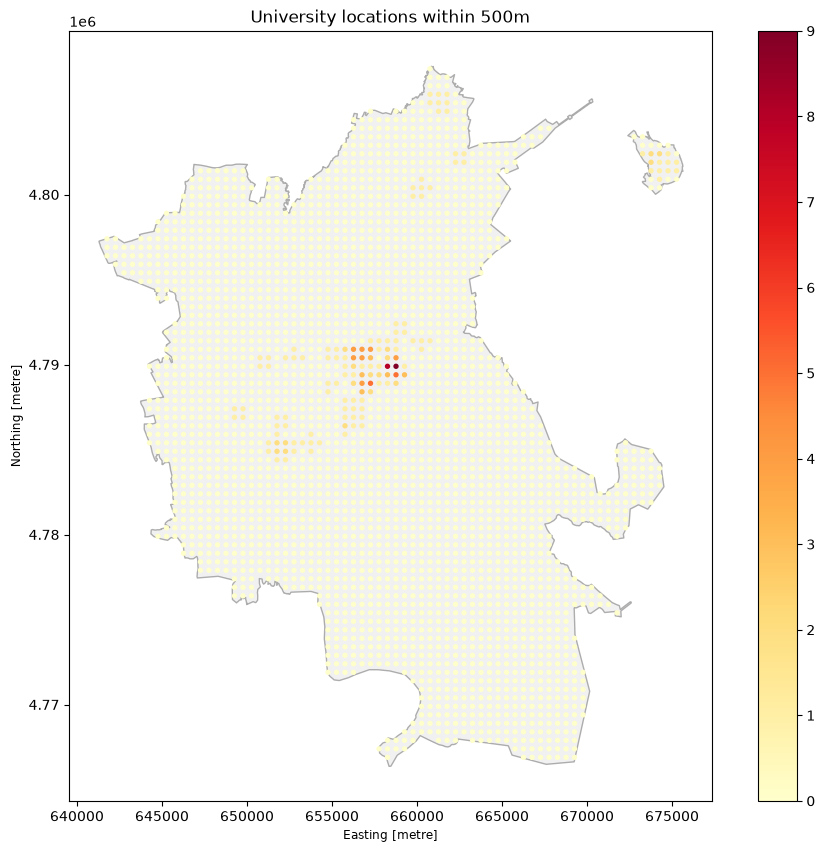

In [120]:
fig, ax = plt.subplots(figsize=(12, 10))

almaty_m.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    alpha=0.3
)

points_inside_city.plot(
    ax=ax,
    column="universities_500m",
    cmap="YlOrRd",
    markersize=8,
    legend=True,
    vmin=0,
    vmax=9
)

ax.set_title("University locations within 500m")
plt.show()

In [121]:
points_inside_city.to_file(
    "../data/processed/candidate_locations.gpkg",
    driver="GPKG"
)

print(points_inside_city.shape)
print(points_inside_city.crs)
print(points_inside_city["universities_500m"].isna().sum())

(2822, 12)
EPSG:32643
0


In [122]:
colleges_poly = gpd.read_file(
    "../data/processed/almaty_colleges_polygons.gpkg"
)

colleges_points = gpd.read_file(
    "../data/processed/almaty_colleges_points.gpkg"
)

print("Полигонов:", len(colleges_poly))
print("Точек:", len(colleges_points))

display(colleges_poly[["name", "amenity"]].head(10))
display(colleges_points[["name", "other_tags"]].head(10))

Полигонов: 14
Точек: 5


,name,amenity
0,Спорт Колледжі,college
1,Алматинский колледж строительства и народных п...,college
2,АГПК,college
3,Алматинский колледж менеджмента и сервиса,college
4,Колледж Декоративно-прикладного искусства Танс...,college
5,Алматинский государственный колледж сервиса и ...,college
6,Учкомбинат,college
7,"Аяжан, медицинский колледж",college
8,А. Селезнёв атындағы Алматы хореография училищесі,college
9,Алматинский электромеханический колледж,college


,name,other_tags
0,Академия транспорта и коммуникаций,"""amenity""=>""college"",""education""=>""college"""
1,Международный колледж бизнеса и коммуникаций,"""amenity""=>""college"",""website""=>""https://icb.kz/"""
2,Инновационный технологический колледж,"""amenity""=>""college"""
3,Евразийский аграрный колледж,"""amenity""=>""college"""
4,Әлеуметтік ғылым колледжі,"""addr:city""=>""Алматы"",""addr:housenumber""=>""4"",..."


In [123]:
colleges_points_m = colleges_points.to_crs(points_inside_city.crs)
colleges_poly_m = colleges_poly.to_crs(points_inside_city.crs)

matches_colleges = gpd.sjoin(
    colleges_points_m,
    colleges_poly_m[['name','geometry']],
    how='left',
    predicate="within",
    lsuffix='point',
    rsuffix='polygon'
)

print(
    "Точек внутри полигонов:",
    matches_colleges.loc[
        matches_colleges["index_polygon"].notna()
    ].index.nunique()
)

display(
    matches_colleges.loc[
        matches_colleges["index_polygon"].notna(),
        ["name_point", "name_polygon"]
    ]
)

Точек внутри полигонов: 0


,name_point,name_polygon


In [124]:
nearest = gpd.sjoin_nearest(
    colleges_points_m,
    colleges_poly_m[["name", "geometry"]],
    how="left",
    distance_col="distance_m",
    lsuffix="point",
    rsuffix="polygon"
)

display(
    nearest[
        ["name_point", "name_polygon", "distance_m"]
    ]
)

,name_point,name_polygon,distance_m
0,Академия транспорта и коммуникаций,А. Селезнёв атындағы Алматы хореография училищесі,2537.443477
1,Международный колледж бизнеса и коммуникаций,Алматинский электромеханический колледж,2928.518373
2,Инновационный технологический колледж,Колледж Декоративно-прикладного искусства Танс...,235.811487
3,Евразийский аграрный колледж,А. Селезнёв атындағы Алматы хореография училищесі,2186.918011
4,Әлеуметтік ғылым колледжі,А. Селезнёв атындағы Алматы хореография училищесі,2078.401210


In [126]:
colleges_poly_work = colleges_poly_m.copy()
colleges_points_work = colleges_points_m.copy()


colleges_poly_work['campus_id'] = (
    'poly_' + colleges_poly_work.index.astype(str)
)
colleges_points_work['campus_id'] = (
    'point_' + colleges_points_work.index.astype(str)
)

colleges_all = gpd.GeoDataFrame(
    pd.concat(
        [colleges_poly_work, colleges_points_work],
        ignore_index=True
    ),
    geometry="geometry",
    crs="EPSG:32643"
)


print("Всего объектов:", len(colleges_all))
print("Уникальных campus_id:", colleges_all["campus_id"].nunique())



Всего объектов: 19
Уникальных campus_id: 19


In [ ]:
# ошибочно были названы уникми

display(universities_poly_m.loc[[6], ["name", "geometry"]])

display(
    universities_points_m.loc[[14, 15], ["name", "geometry"]]
)

,name,geometry
6,Алматинский Финансово-Экономический Колледж,"MULTIPOLYGON (((651958.458 4785299.663, 651993..."


,name,geometry
14,Казахстанско-Российский Высшый Медицинский Кол...,POINT (657042.107 4790565.974)
15,Орта Азия техникалық-экономикалық колледжі,POINT (658932.464 4789441.916)


In [128]:
extra_colleges = gpd.GeoDataFrame(
    pd.concat(
        [
            universities_poly_m.loc[[6]],
            universities_points_m.loc[[14, 15]]
        ]
    ),
    geometry="geometry",
    crs="EPSG:32643"
).copy()

extra_colleges["campus_id"] = [
    "reclassified_poly_6",
    "reclassified_point_14",
    "reclassified_point_15"
]

print("Дополнительных колледжей:", len(extra_colleges))
display(extra_colleges[["name", "campus_id"]])

Дополнительных колледжей: 3


,name,campus_id
6,Алматинский Финансово-Экономический Колледж,reclassified_poly_6
14,Казахстанско-Российский Высшый Медицинский Кол...,reclassified_point_14
15,Орта Азия техникалық-экономикалық колледжі,reclassified_point_15


In [129]:
colleges_all = gpd.GeoDataFrame(
    pd.concat(
        [colleges_all, extra_colleges], 
        ignore_index=True
    ),
     geometry="geometry",
     crs="EPSG:32643"
)

print("Всего объектов:", len(colleges_all))
print("Уникальных campus_id:", colleges_all["campus_id"].nunique())



Всего объектов: 22
Уникальных campus_id: 22


In [130]:
nearest_extra = gpd.sjoin_nearest(
    extra_colleges,
    colleges_all.iloc[:19][["name", "geometry"]],
    how="left",
    distance_col="distance_m",
    lsuffix="extra",
    rsuffix="existing"
)

display(
    nearest_extra[
        ["name_extra", "name_existing", "distance_m"]
    ]
)

,name_extra,name_existing,distance_m
6,Алматинский Финансово-Экономический Колледж,Алматинский колледж менеджмента и сервиса,1363.781030
14,Казахстанско-Российский Высшый Медицинский Кол...,А. Селезнёв атындағы Алматы хореография училищесі,592.317741
15,Орта Азия техникалық-экономикалық колледжі,Әлеуметтік ғылым колледжі,280.232490


In [131]:
misclassified_geometries = extra_colleges.geometry

universities_all_clean = universities_all[
    ~universities_all.geometry.apply(
        lambda geom: misclassified_geometries.geom_equals(geom).any()
    )
].copy()

print("Было университетских объектов:", len(universities_all))
print("Стало:", len(universities_all_clean))

Было университетских объектов: 45
Стало: 42


In [132]:
universities_500m = []

for point in points_inside_city.geometry:
    result = count_nearby_campuses(
        point,
        universities_all_clean,
        500
    )
    universities_500m.append(result)

points_inside_city["universities_500m"] = universities_500m


print(points_inside_city["universities_500m"].describe())

print(
    "Точек рядом с университетами:",
    (points_inside_city["universities_500m"] > 0).sum()
)

print(
    "Максимум университетских локаций:",
    points_inside_city["universities_500m"].max()
)

count    2822.000000
mean        0.068037
std         0.393557
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         8.000000
Name: universities_500m, dtype: float64
Точек рядом с университетами: 132
Максимум университетских локаций: 8


In [133]:
colleges_500m = []

for point in points_inside_city.geometry:
    result = count_nearby_campuses(
        point,
        colleges_all,
        500
    )
    colleges_500m.append(result)

points_inside_city["colleges_500m"] = colleges_500m


print(points_inside_city["colleges_500m"].describe())

print(
    "Точек рядом с колледжами:",
    (points_inside_city["colleges_500m"] > 0).sum()
)

print(
    "Максимум колледжских локаций:",
    points_inside_city["colleges_500m"].max()
)

count    2822.000000
mean        0.028349
std         0.182282
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         2.000000
Name: colleges_500m, dtype: float64
Точек рядом с колледжами: 72
Максимум колледжских локаций: 2


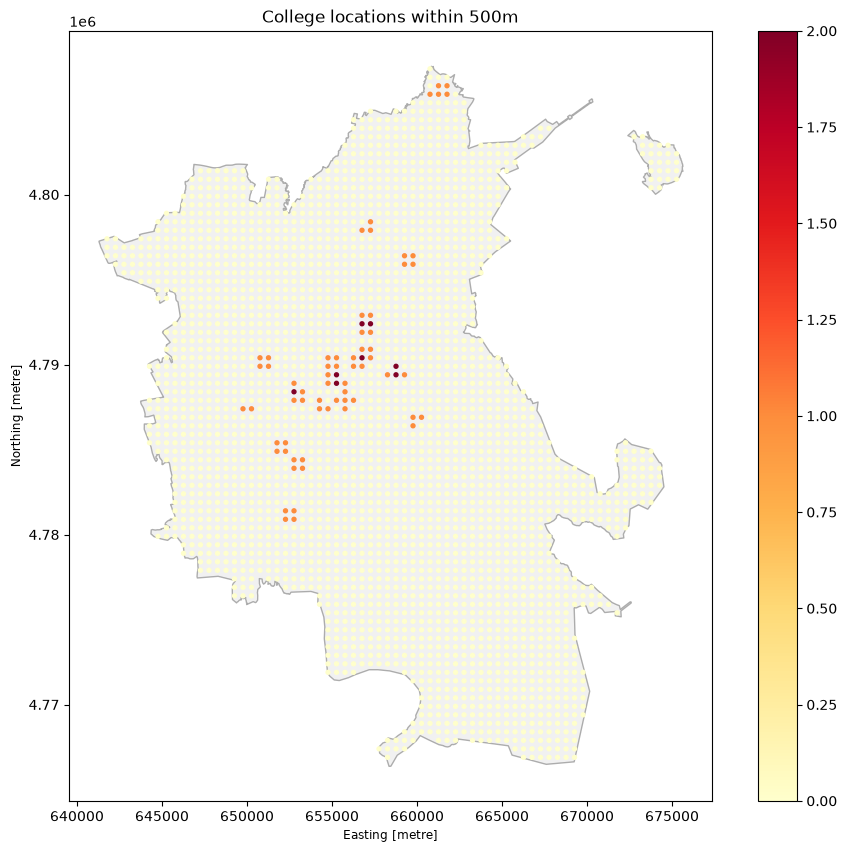

In [134]:
fig, ax = plt.subplots(figsize=(12, 10))

almaty_m.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    alpha=0.3
)

points_inside_city.plot(
    ax=ax,
    column="colleges_500m",
    cmap="YlOrRd",
    markersize=8,
    legend=True,
    vmin=0,
    vmax=2
)

ax.set_title("College locations within 500m")
plt.show()

In [135]:
points_inside_city.to_file(
    "../data/processed/candidate_locations.gpkg",
    driver="GPKG"
)

print(points_inside_city.shape)
print(points_inside_city.crs)

print(
    points_inside_city[
        ["universities_500m", "colleges_500m"]
    ].isna().sum()
)

(2822, 13)
EPSG:32643
universities_500m    0
colleges_500m        0
dtype: int64
